Name: Darshit Saini

Student ID: 202451044

# Gaussian Mixture Model using Expectation Maximization

## Aim

To generate 3 two-dimensional Gaussian clusters and implement the Gaussian Mixture Model using the Expectation Maximization algorithm with diagonal covariance matrices. The clustering obtained using GMM-EM is then compared with K-means clustering.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.patches import Ellipse
from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment

## 1. Data Generation

3 two-dimensional Gaussian clusters are generated. Each cluster contains 150 points. Different means and standard deviations are used so that the clusters have different locations, shapes and variances.

In [3]:
np.random.seed(42)

# Number of points in each cluster
n_per_cluster = 150

# Means of the three Gaussian clusters
true_means = np.array([
    [-3.0, 0.0],
    [0.0, 3.0],
    [3.0, 0.0]
])

# Standard deviations in x and y directions
true_stds = np.array([
    [1.6, 0.5],
    [0.6, 1.7],
    [1.0, 0.9]
])

X_list = []
true_labels = []

for i in range(3):
    cluster = np.random.normal(
        loc=true_means[i],
        scale=true_stds[i],
        size=(n_per_cluster, 2)
    )

    X_list.append(cluster)
    true_labels.extend([i] * n_per_cluster)

# Combine all clusters
X = np.vstack(X_list)

true_labels = np.array(true_labels)

print("Dataset shape:", X.shape)
print("Number of points:", len(X))

Dataset shape: (450, 2)
Number of points: 450


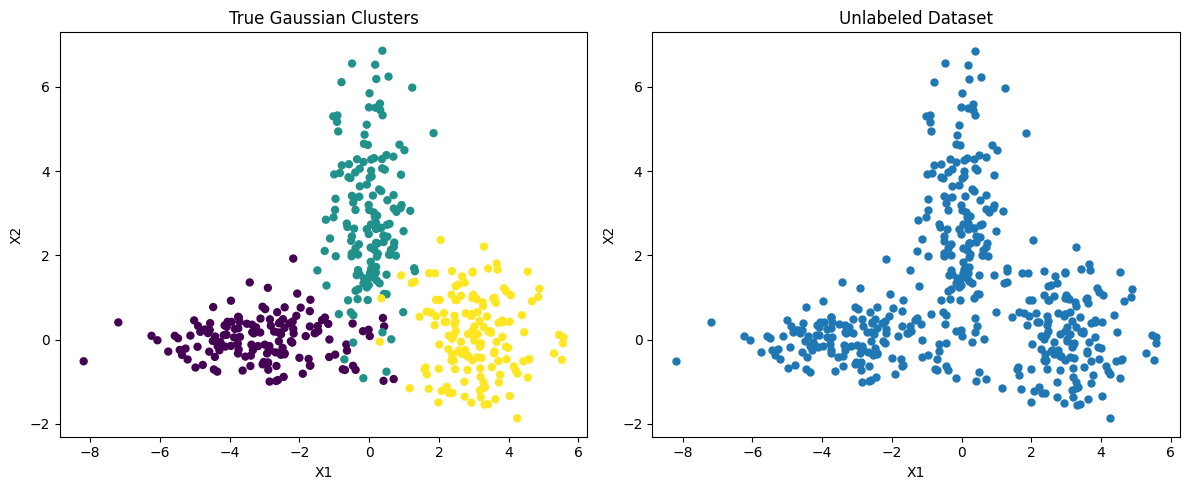

In [4]:
plt.figure(figsize=(12, 5))

# True clusters
plt.subplot(1, 2, 1)

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=true_labels,
    cmap="viridis",
    s=25
)

plt.title("True Gaussian Clusters")
plt.xlabel("X1")
plt.ylabel("X2")

# Unlabeled data
plt.subplot(1, 2, 2)
plt.scatter(
    X[:, 0],
    X[:, 1],
    s=25
)

plt.title("Unlabeled Dataset")
plt.xlabel("X1")
plt.ylabel("X2")

plt.tight_layout()
plt.show()

### Observation

The dataset contains 450 two-dimensional observations divided equally among 3 Gaussian clusters. The clusters have different means and different variances. The second plot represents the same dataset without using the true labels, which is the input given to the clustering algorithms.

## 2. GMM using Expectation Maximization

The GMM is implemented manually.

The EM algorithm repeatedly performs the E-step and M-step until the change in log-likelihood becomes sufficiently small.

In [5]:
def initialize_gmm(X, K, seed=7):

    rng = np.random.default_rng(seed)

    # Randomly select K data points as initial means
    selected = rng.choice(
        len(X),
        size=K,
        replace=False
    )

    means = X[selected].copy()

    # Initial variance = variance of the complete dataset
    global_variance = np.var(X, axis=0)

    variances = np.tile(
        global_variance,
        (K, 1)
    )

    # Initially assume every cluster is equally likely
    weights = np.ones(K) / K

    return means, variances, weights

In [6]:
def gaussian_pdf_diag(X, mean, variance):

    d = X.shape[1]

    # Constant part
    coefficient = 1.0 / np.sqrt(
        ((2 * np.pi) ** d) * np.prod(variance)
    )

    # Exponential part
    exponent = -0.5 * np.sum(
        ((X - mean) ** 2) / variance,
        axis=1
    )

    return coefficient * np.exp(exponent)

In [7]:
def e_step(X, means, variances, weights):

    N = len(X)
    K = len(weights)

    weighted_probabilities = np.zeros((N, K))

    # Probability of every point under every Gaussian
    for k in range(K):

        weighted_probabilities[:, k] = (
            weights[k]
            * gaussian_pdf_diag(
                X,
                means[k],
                variances[k]
            )
        )

    # Total probability of each data point
    total_probability = (
        weighted_probabilities.sum(axis=1, keepdims=True)
        + 1e-12
    )

    # Responsibilities
    responsibilities = (
        weighted_probabilities
        / total_probability
    )

    # Log-likelihood
    log_likelihood = np.sum(
        np.log(total_probability[:, 0])
    )

    return responsibilities, log_likelihood

In [8]:
def m_step(X, responsibilities):

    N, K = responsibilities.shape

    # Effective number of points belonging to each cluster
    Nk = responsibilities.sum(axis=0) + 1e-12

    weights = Nk / N

    means = (
        responsibilities.T @ X
    ) / Nk[:, None]

    variances = np.zeros(
        (K, X.shape[1])
    )

    for k in range(K):

        difference = X - means[k]

        variances[k] = np.sum(
            responsibilities[:, k, None]
            * (difference ** 2),
            axis=0
        ) / Nk[k]


    # Preventing variance from becoming zero
    variances += 1e-6

    return means, variances, weights

In [9]:
def fit_gmm_em(
    X,
    K=3,
    max_iterations=200,
    tolerance=1e-4
):

    means, variances, weights = initialize_gmm(
        X,
        K
    )

    log_likelihoods = []

    for iteration in range(max_iterations):

        # E-step
        responsibilities, log_likelihood = e_step(
            X,
            means,
            variances,
            weights
        )

        log_likelihoods.append(log_likelihood)


        # M-step
        means, variances, weights = m_step(
            X,
            responsibilities
        )


        # Check convergence
        if iteration > 0:

            difference = abs(
                log_likelihoods[-1]
                - log_likelihoods[-2]
            )

            if difference < tolerance:
                break


    # Final responsibilities
    responsibilities, _ = e_step(
        X,
        means,
        variances,
        weights
    )

    # Hard cluster assignment
    labels = np.argmax(
        responsibilities,
        axis=1
    )

    return (
        labels,
        means,
        variances,
        weights,
        log_likelihoods
    )

In [10]:
gmm_labels, gmm_means, gmm_variances, gmm_weights, log_likelihoods = fit_gmm_em(
    X,
    K=3
)

print("Number of EM iterations:")
print(len(log_likelihoods))

print("\nLearned Means:")
print(gmm_means)

print("\nLearned Variances:")
print(gmm_variances)

print("\nLearned Mixture Weights:")
print(gmm_weights)

Number of EM iterations:
32

Learned Means:
[[-3.1921646   0.01519341]
 [ 0.01151889  2.744321  ]
 [ 3.07371825  0.09491578]]

Learned Variances:
[[2.06397307 0.22610418]
 [0.39393236 2.78164625]
 [0.89526993 0.81203148]]

Learned Mixture Weights:
[0.31749869 0.35536466 0.32713665]


In [11]:
def draw_ellipse(mean, variance, ax, n_std=2):

    width = 2 * n_std * np.sqrt(variance[0])
    height = 2 * n_std * np.sqrt(variance[1])

    ellipse = Ellipse(
        xy=mean,
        width=width,
        height=height,
        angle=0,
        fill=False,
        linewidth=2
    )

    ax.add_patch(ellipse)

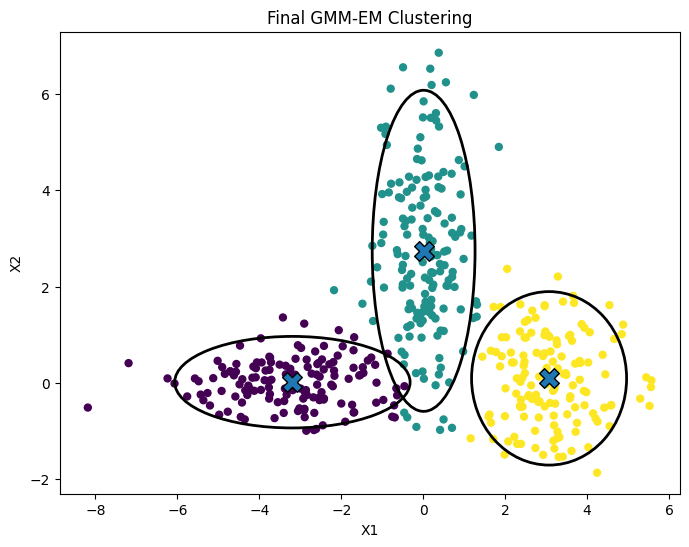

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    X[:, 0],
    X[:, 1],
    c=gmm_labels,
    cmap="viridis",
    s=25
)

# Plot learned Gaussian means
ax.scatter(
    gmm_means[:, 0],
    gmm_means[:, 1],
    marker="X",
    s=200,
    edgecolor="black"
)

# Draw Gaussian ellipses
for k in range(3):

    draw_ellipse(
        gmm_means[k],
        gmm_variances[k],
        ax
    )

ax.set_title("Final GMM-EM Clustering")
ax.set_xlabel("X1")
ax.set_ylabel("X2")

plt.show()

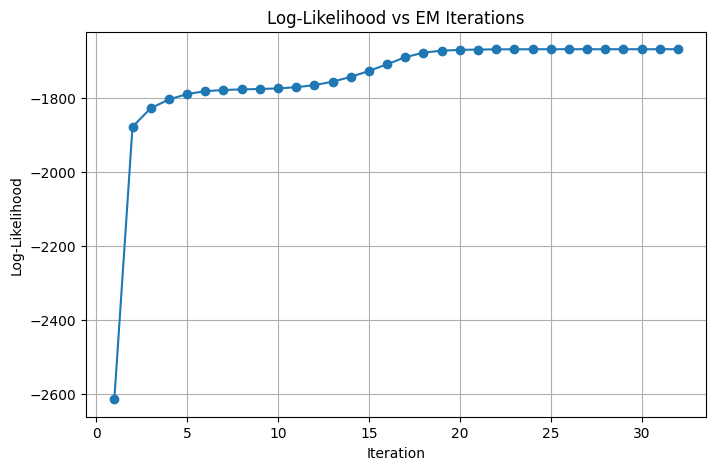

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(log_likelihoods) + 1),
    log_likelihoods,
    marker="o"
)

plt.xlabel("Iteration")
plt.ylabel("Log-Likelihood")

plt.title(
    "Log-Likelihood vs EM Iterations"
)

plt.grid()

plt.show()

### Observation

The log-likelihood increases rapidly during the initial EM iterations and then gradually becomes stable. Once the absolute change in log-likelihood falls below the selected tolerance, the algorithm is considered to have converged. This shows that the EM algorithm iteratively improves the parameters of the Gaussian mixture model.

## 4. Comparison with K-Means

K-means clustering is applied to the same unlabeled dataset using three clusters. Unlike GMM, K-means assigns points according to their Euclidean distance from cluster centroids and does not explicitly model cluster variance.

In [14]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X)

kmeans_centers = kmeans.cluster_centers_

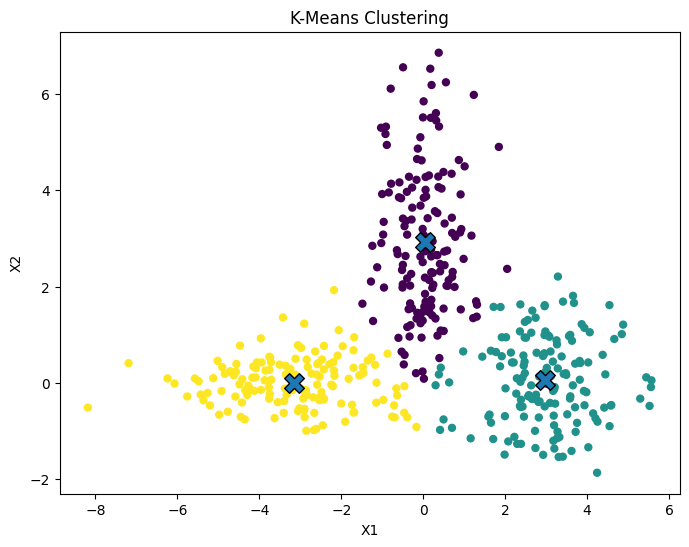

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=25
)

plt.scatter(
    kmeans_centers[:, 0],
    kmeans_centers[:, 1],
    marker="X",
    s=200,
    edgecolor="black"
)

plt.title("K-Means Clustering")

plt.xlabel("X1")
plt.ylabel("X2")

plt.show()

In [16]:
K = 3

# Creating a matrix showing how GMM and K-means labels overlap
overlap_matrix = np.zeros(
    (K, K),
    dtype=int
)

for gmm_label, kmeans_label in zip(
    gmm_labels,
    kmeans_labels
):

    overlap_matrix[
        gmm_label,
        kmeans_label
    ] += 1


# Finding the best matching between labels
rows, columns = linear_sum_assignment(
    -overlap_matrix
)


# Mapping K-means labels to GMM labels
label_mapping = {}

for gmm_label, kmeans_label in zip(
    rows,
    columns
):

    label_mapping[kmeans_label] = gmm_label


# Applying mapping
aligned_kmeans_labels = np.array([
    label_mapping[label]
    for label in kmeans_labels
])

In [17]:
different_points = np.where(
    gmm_labels != aligned_kmeans_labels
)[0]

print(
    "Number of points with different assignments:",
    len(different_points)
)

Number of points with different assignments: 13


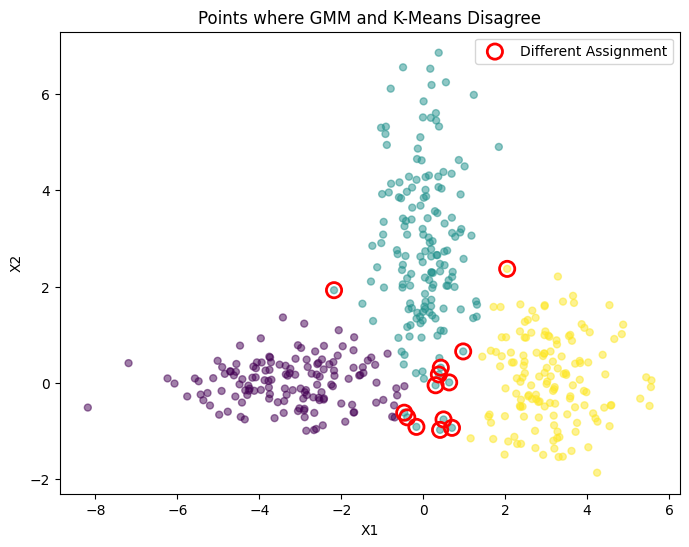

In [18]:
plt.figure(figsize=(8, 6))

# Ploting all points according to GMM
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=gmm_labels,
    cmap="viridis",
    s=25,
    alpha=0.5
)

# Highlighting disagreement points
plt.scatter(
    X[different_points, 0],
    X[different_points, 1],
    facecolors="none",
    edgecolors="red",
    s=120,
    linewidths=2,
    label="Different Assignment"
)

plt.title(
    "Points where GMM and K-Means Disagree"
)

plt.xlabel("X1")
plt.ylabel("X2")

plt.legend()

plt.show()

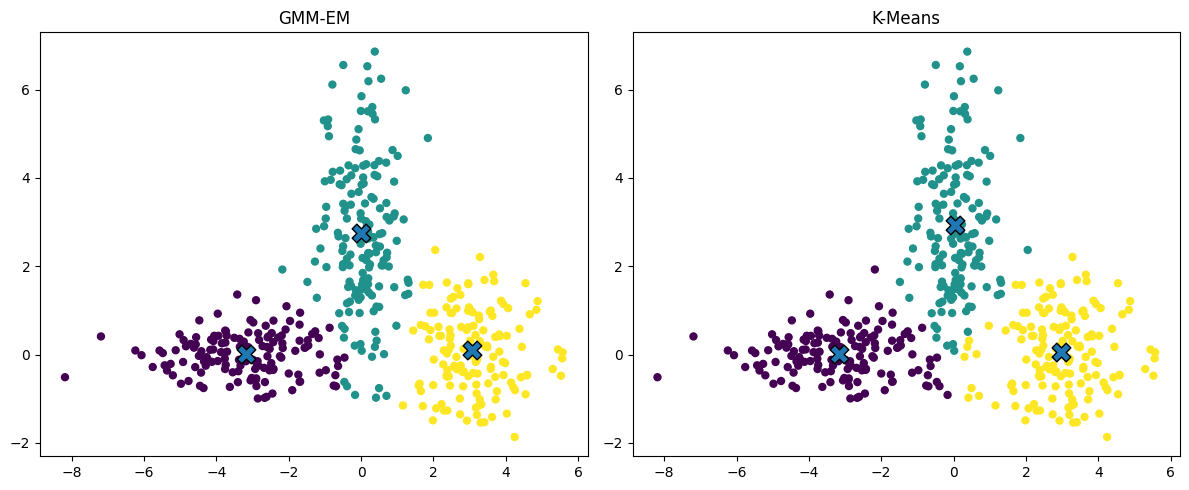

In [19]:
plt.figure(figsize=(12, 5))


# GMM
plt.subplot(1, 2, 1)

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=gmm_labels,
    cmap="viridis",
    s=25
)

plt.scatter(
    gmm_means[:, 0],
    gmm_means[:, 1],
    marker="X",
    s=180,
    edgecolor="black"
)

plt.title("GMM-EM")


# K-means
plt.subplot(1, 2, 2)

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=aligned_kmeans_labels,
    cmap="viridis",
    s=25
)

plt.scatter(
    kmeans_centers[:, 0],
    kmeans_centers[:, 1],
    marker="X",
    s=180,
    edgecolor="black"
)

plt.title("K-Means")


plt.tight_layout()
plt.show()

## 5. Analysis

The GMM-EM and K-means algorithms produce similar cluster assignments for most of the observations. However, some points near the boundaries of the clusters receive different assignments.

In this experiment, approximately 13 points are assigned to different clusters by GMM and K-means.

The difference occurs because K-means and GMM make different assumptions about the structure of clusters.

K-means assigns every observation to the nearest centroid according to Euclidean distance. Therefore, its cluster boundaries depend mainly on the distance of points from the cluster centers. K-means works particularly well when clusters are approximately spherical and have similar sizes and variances.

GMM, on the other hand, models every cluster as a Gaussian probability distribution. It considers not only the cluster mean but also the variance of each cluster and its mixture probability.

In the generated dataset, the three clusters have different variances. For example, one cluster is more spread in the horizontal direction whereas another is more spread in the vertical direction. Therefore, a point may be closer to one K-means centroid but may have a higher probability under another Gaussian distribution.

As a result, points in overlapping or boundary regions may receive different assignments from GMM and K-means.

Thus, GMM is better able to represent clusters having different shapes and variances, whereas K-means mainly creates distance-based partitions around the cluster centroids.

## Conclusion

3 two-dimensional Gaussian clusters containing 150 observations each were generated and used as an unlabeled dataset.

A Gaussian Mixture Model was implemented manually using the Expectation Maximization algorithm. The implementation consisted of initialization, E-step, M-step and convergence checking using log-likelihood. Diagonal covariance matrices were used as required.

The log-likelihood increased with successive EM iterations and eventually converged, showing that the model parameters were being optimized.

K-means was also applied to the same dataset. Both algorithms successfully identified the major cluster structure, but some observations near overlapping cluster boundaries received different assignments.

The difference occurs because K-means uses Euclidean distance from centroids, whereas GMM considers the probability distribution, variance and mixture weight of each cluster. Therefore, GMM can better represent clusters having unequal variances and non-uniform shapes.